In [1]:
import pandas as pd

# Load dataset
df = pd.read_csv("Nassau Candy Distributor.csv")

# Convert dates
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y"
)

# Calculate lead time in days
df["Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

print("Rows:", len(df))
print("Columns:", len(df.columns))

Rows: 10194
Columns: 19


In [2]:
df.head()

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912


In [3]:
df.columns

Index(['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode',
       'Customer ID', 'Country/Region', 'City', 'State/Province',
       'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name',
       'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time'],
      dtype='object')

In [4]:
df.shape

(10194, 19)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10194 entries, 0 to 10193
Data columns (total 19 columns):
 #   Column          Non-Null Count  Dtype         
---  ------          --------------  -----         
 0   Row ID          10194 non-null  int64         
 1   Order ID        10194 non-null  object        
 2   Order Date      10194 non-null  datetime64[ns]
 3   Ship Date       10194 non-null  datetime64[ns]
 4   Ship Mode       10194 non-null  object        
 5   Customer ID     10194 non-null  int64         
 6   Country/Region  10194 non-null  object        
 7   City            10194 non-null  object        
 8   State/Province  10194 non-null  object        
 9   Postal Code     10194 non-null  object        
 10  Division        10194 non-null  object        
 11  Region          10194 non-null  object        
 12  Product ID      10194 non-null  object        
 13  Product Name    10194 non-null  object        
 14  Sales           10194 non-null  float64       
 15  Un

In [6]:
df.describe()

,Row ID,Order Date,Ship Date,Customer ID,Sales,Units,Gross Profit,Cost,Lead Time
count,10194.000000,10194,10194,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000,10194.000000
mean,5097.500000,2025-03-13 03:08:26.415538176,2028-10-23 23:20:43.790465024,134468.961154,13.908537,3.791838,9.166451,4.742087,1320.841868
min,1.000000,2024-01-02 00:00:00,2026-06-30 00:00:00,100006.000000,1.250000,1.000000,0.250000,0.600000,904.000000
25%,2549.250000,2024-09-28 00:00:00,2027-11-09 00:00:00,117212.000000,7.200000,2.000000,4.900000,2.400000,1271.000000
50%,5097.500000,2025-04-06 12:00:00,2028-12-18 00:00:00,133550.000000,10.800000,3.000000,7.470000,3.600000,1274.000000
75%,7645.750000,2025-09-16 00:00:00,2029-11-08 00:00:00,152051.000000,18.000000,5.000000,12.250000,5.700000,1638.000000
max,10194.000000,2025-12-31 00:00:00,2030-06-28 00:00:00,192314.000000,260.000000,14.000000,130.000000,130.000000,1642.000000
std,2942.898656,NaN,NaN,20231.483007,11.341020,2.228317,6.643740,5.061647,262.444892


In [7]:
df.duplicated().sum()

np.int64(0)

In [8]:
df["Order Date"] = pd.to_datetime(df["Order Date"], dayfirst=True)
df["Ship Date"] = pd.to_datetime(df["Ship Date"], dayfirst=True)

df["Lead Time"] = (df["Ship Date"] - df["Order Date"]).dt.days

df[["Order Date", "Ship Date", "Lead Time"]].head()

,Order Date,Ship Date,Lead Time
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [9]:
df["Lead Time"].describe()

count    10194.000000
mean      1320.841868
std        262.444892
min        904.000000
25%       1271.000000
50%       1274.000000
75%       1638.000000
max       1642.000000
Name: Lead Time, dtype: float64

In [10]:
df["Ship Mode"].value_counts()

Ship Mode
Standard Class    6120
Second Class      1979
First Class       1548
Same Day           547
Name: count, dtype: int64

In [11]:
df.groupby("Ship Mode")["Lead Time"].mean().sort_values()

Ship Mode
Standard Class    1314.334641
Second Class      1323.845376
Same Day          1333.442413
First Class       1338.275840
Name: Lead Time, dtype: float64

In [12]:
df.groupby("Region")["Lead Time"].mean().sort_values(ascending=False)

Region
Interior    1323.091221
Atlantic    1322.745144
Pacific     1322.194897
Gulf        1311.374691
Name: Lead Time, dtype: float64

In [13]:
df.groupby("State/Province")["Lead Time"].mean().sort_values(ascending=False).head(10)

State/Province
West Virginia           1638.000000
North Dakota            1637.857143
Saskatchewan            1457.000000
Manitoba                1455.333333
Iowa                    1443.900000
New Mexico              1441.837838
Vermont                 1438.909091
Prince Edward Island    1420.300000
South Dakota            1395.916667
Tennessee               1391.486339
Name: Lead Time, dtype: float64

In [14]:
df.groupby("Product Name")["Lead Time"].mean().sort_values(ascending=False).head(10)

Product Name
Hair Toffee                          1455.250000
Everlasting Gobstopper               1394.666667
SweeTARTS                            1383.500000
Laffy Taffy                          1383.100000
Lickable Wallpaper                   1339.138298
Wonka Bar - Nutty Crunch Surprise    1328.915470
Wonka Bar - Triple Dazzle Caramel    1325.661042
Wonka Bar -Scrumdiddlyumptious       1320.641957
Wonka Bar - Milk Chocolate           1316.764623
Wonka Bar - Fudge Mallows            1314.242024
Name: Lead Time, dtype: float64

In [15]:
df["Product Name"].value_counts().head(10)

Product Name
Wonka Bar - Milk Chocolate           2137
Wonka Bar -Scrumdiddlyumptious       2064
Wonka Bar - Triple Dazzle Caramel    2015
Wonka Bar - Fudge Mallows            1818
Wonka Bar - Nutty Crunch Surprise    1810
Wonka Gum                             120
Kazookles                              96
Lickable Wallpaper                     94
Laffy Taffy                            10
SweeTARTS                              10
Name: count, dtype: int64

In [16]:
product_analysis = df.groupby("Product Name").agg(
    Orders=("Product Name", "count"),
    Average_Lead_Time=("Lead Time", "mean")
)

product_analysis.sort_values(
    by=["Orders", "Average_Lead_Time"],
    ascending=False
).head(10)

,Orders,Average_Lead_Time
Product Name,,
Wonka Bar - Milk Chocolate,2137,1316.764623
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042
Wonka Bar - Fudge Mallows,1818,1314.242024
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470
Wonka Gum,120,1306.525000
Kazookles,96,1272.989583
Lickable Wallpaper,94,1339.138298
SweeTARTS,10,1383.500000


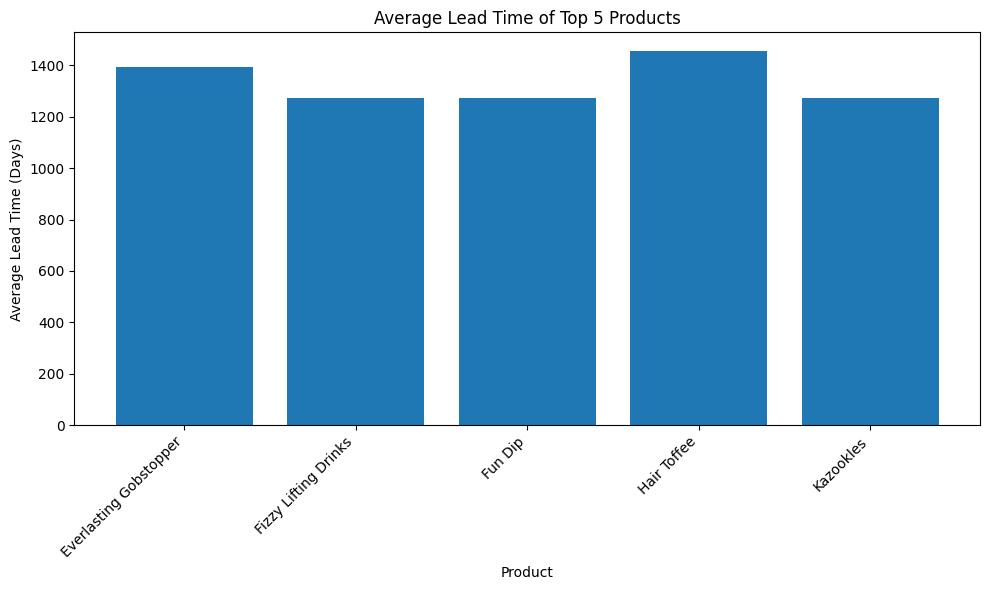

In [17]:
import matplotlib.pyplot as plt

top_products = product_analysis.head(5)

plt.figure(figsize=(10, 6))
plt.bar(top_products.index, top_products["Average_Lead_Time"])

plt.title("Average Lead Time of Top 5 Products")
plt.xlabel("Product")
plt.ylabel("Average Lead Time (Days)")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [18]:
import matplotlib.pyplot as plt

In [19]:
import pandas as pd

In [20]:
import matplotlib.pyplot as plt

In [21]:
pd.read_csv("Nassau Candy Distributor.csv")

,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost
0,1,US-2021-103800-CHO-MIL-31000,03-01-2024,30-06-2026,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28
1,2,US-2021-112326-CHO-TRI-54000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60
2,3,US-2021-112326-CHO-NUT-13000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00
3,4,US-2021-112326-CHO-SCR-58000,04-01-2024,01-07-2026,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
4,5,US-2021-141817-CHO-TRI-54000,05-01-2024,05-07-2026,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
10189,10190,US-2024-143259-CHO-MIL-31000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-MIL-31000,Wonka Bar - Milk Chocolate,9.75,3,6.33,3.42
10190,10191,US-2024-115427-CHO-NUT-13000,30-12-2025,26-06-2030,Standard Class,115427,United States,Fairfield,California,94533,Chocolate,Pacific,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,6.98,2,4.98,2.00
10191,10192,US-2024-156720-CHO-SCR-58000,30-12-2025,26-06-2030,Standard Class,156720,United States,Loveland,Colorado,80538,Chocolate,Pacific,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30
10192,10193,US-2024-143259-CHO-TRI-54000,30-12-2025,26-06-2030,Standard Class,143259,United States,New York City,New York,10009,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,26.25,7,17.15,9.10


In [22]:
import pandas as pd

# Load the dataset
df = pd.read_csv("Nassau Candy Distributor.csv")

# Convert dates from DD-MM-YYYY
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y"
)

# Calculate lead time
df["Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Check the data
print("Rows:", len(df))
print("Columns:", len(df.columns))

df.head()

Rows: 10194
Columns: 19


,Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Country/Region,City,State/Province,Postal Code,Division,Region,Product ID,Product Name,Sales,Units,Gross Profit,Cost,Lead Time
0,1,US-2021-103800-CHO-MIL-31000,2024-01-03,2026-06-30,Standard Class,103800,United States,Houston,Texas,77095,Chocolate,Interior,CHO-MIL-31000,Wonka Bar - Milk Chocolate,6.50,2,4.22,2.28,909
1,2,US-2021-112326-CHO-TRI-54000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,7.50,2,4.90,2.60,909
2,3,US-2021-112326-CHO-NUT-13000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-NUT-13000,Wonka Bar - Nutty Crunch Surprise,10.47,3,7.47,3.00,909
3,4,US-2021-112326-CHO-SCR-58000,2024-01-04,2026-07-01,Standard Class,112326,United States,Naperville,Illinois,60540,Chocolate,Interior,CHO-SCR-58000,Wonka Bar -Scrumdiddlyumptious,10.80,3,7.50,3.30,909
4,5,US-2021-141817-CHO-TRI-54000,2024-01-05,2026-07-05,Standard Class,141817,United States,Philadelphia,Pennsylvania,19143,Chocolate,Atlantic,CHO-TRI-54000,Wonka Bar - Triple Dazzle Caramel,11.25,3,7.35,3.90,912


In [23]:
df[["Order Date", "Ship Date", "Lead Time"]].head()

,Order Date,Ship Date,Lead Time
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [24]:
ship_mode_analysis = (
    df.groupby("Ship Mode")["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

ship_mode_analysis

,count,mean,median
Ship Mode,,,
First Class,1548,1338.275840,1272.0
Same Day,547,1333.442413,1269.0
Second Class,1979,1323.845376,1273.0
Standard Class,6120,1314.334641,1274.0


In [25]:
# Analyze lead time by product

product_analysis = (
    df.groupby("Product Name")["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

product_analysis.head(10)

,count,mean,median
Product Name,,,
Hair Toffee,4,1455.250000,1455.0
Everlasting Gobstopper,3,1394.666667,1273.0
SweeTARTS,10,1383.500000,1274.0
Laffy Taffy,10,1383.100000,1275.0
Lickable Wallpaper,94,1339.138298,1274.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1274.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1274.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1274.0
Wonka Bar - Milk Chocolate,2137,1316.764623,1274.0


In [26]:
# Keep only products with enough orders for meaningful analysis

reliable_products = product_analysis[
    product_analysis["count"] >= 20
].copy()

reliable_products = reliable_products.sort_values(
    "mean",
    ascending=False
)

reliable_products.head(10)

,count,mean,median
Product Name,,,
Lickable Wallpaper,94,1339.138298,1274.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1274.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1274.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1274.0
Wonka Bar - Milk Chocolate,2137,1316.764623,1274.0
Wonka Bar - Fudge Mallows,1818,1314.242024,1274.0
Wonka Gum,120,1306.525000,1273.5
Kazookles,96,1272.989583,1273.0


In [27]:
# Calculate a hypothetical 10% lead-time reduction

reliable_products["Potential_Reduction_10%"] = (
    reliable_products["mean"] * 0.10
)

reliable_products["Projected_Lead_Time"] = (
    reliable_products["mean"] * 0.90
)

reliable_products[
    ["count", "mean", "Potential_Reduction_10%", "Projected_Lead_Time"]
]

,count,mean,Potential_Reduction_10%,Projected_Lead_Time
Product Name,,,,
Lickable Wallpaper,94,1339.138298,133.913830,1205.224468
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,132.891547,1196.023923
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,132.566104,1193.094938
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,132.064196,1188.577762
Wonka Bar - Milk Chocolate,2137,1316.764623,131.676462,1185.088161
Wonka Bar - Fudge Mallows,1818,1314.242024,131.424202,1182.817822
Wonka Gum,120,1306.525000,130.652500,1175.872500
Kazookles,96,1272.989583,127.298958,1145.690625


In [28]:
# Calculate total potential savings

total_saved = (
    reliable_products["Potential_Reduction_10%"]
    * reliable_products["count"]
).sum()

total_orders = reliable_products["count"].sum()

average_saving_per_order = total_saved / total_orders

print("Total Potential Lead-Time Saved:", round(total_saved, 2))
print("Average Potential Saving per Order:", round(average_saving_per_order, 2))

Total Potential Lead-Time Saved: 1341043.6
Average Potential Saving per Order: 132.07


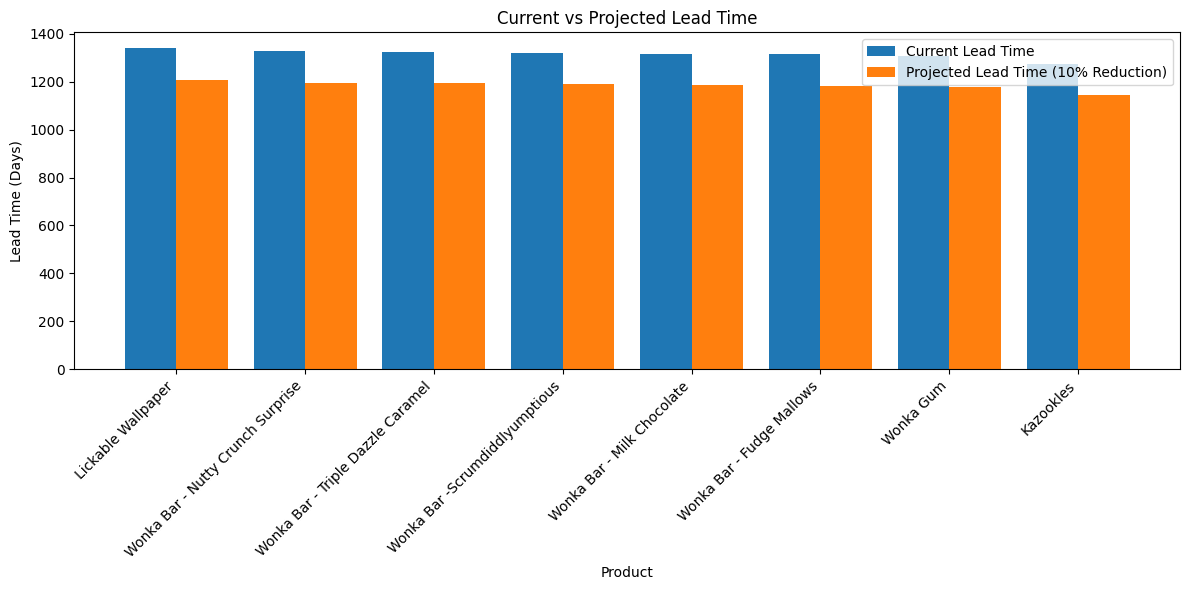

In [29]:
import matplotlib.pyplot as plt

# Compare current and projected lead time
plt.figure(figsize=(12, 6))

x = range(len(reliable_products))

plt.bar(
    [i - 0.2 for i in x],
    reliable_products["mean"],
    width=0.4,
    label="Current Lead Time"
)

plt.bar(
    [i + 0.2 for i in x],
    reliable_products["Projected_Lead_Time"],
    width=0.4,
    label="Projected Lead Time (10% Reduction)"
)

plt.xticks(
    x,
    reliable_products.index,
    rotation=45,
    ha="right"
)

plt.xlabel("Product")
plt.ylabel("Lead Time (Days)")
plt.title("Current vs Projected Lead Time")
plt.legend()

plt.tight_layout()
plt.show()

In [30]:
# Final optimization KPI summary

print("=" * 55)
print("NASSAU CANDY DISTRIBUTION - OPTIMIZATION KPIs")
print("=" * 55)

print(f"Total Orders Analyzed: {len(df):,}")
print(f"Overall Average Lead Time: {df['Lead Time'].mean():.2f} days")
print(f"Overall Median Lead Time: {df['Lead Time'].median():.2f} days")

print("\n2024 vs 2025:")
print(
    f"2024 Average Lead Time: "
    f"{df[df['Order Date'].dt.year == 2024]['Lead Time'].mean():.2f} days"
)

print(
    f"2025 Average Lead Time: "
    f"{df[df['Order Date'].dt.year == 2025]['Lead Time'].mean():.2f} days"
)

print("\nOptimization Scenario (10% Reduction):")
print(f"Products Analyzed: {len(reliable_products)}")
print(f"Total Potential Lead-Time Saved: {total_saved:,.2f} days")
print(f"Average Potential Saving per Order: {average_saving_per_order:.2f} days")

print("\nPriority Products:")
print(reliable_products[["count", "mean"]].head(5))

NASSAU CANDY DISTRIBUTION - OPTIMIZATION KPIs
Total Orders Analyzed: 10,194
Overall Average Lead Time: 1320.84 days
Overall Median Lead Time: 1274.00 days

2024 vs 2025:
2024 Average Lead Time: 1094.02 days
2025 Average Lead Time: 1478.56 days

Optimization Scenario (10% Reduction):
Products Analyzed: 8
Total Potential Lead-Time Saved: 1,341,043.60 days
Average Potential Saving per Order: 132.07 days

Priority Products:
                                   count         mean
Product Name                                         
Lickable Wallpaper                    94  1339.138298
Wonka Bar - Nutty Crunch Surprise   1810  1328.915470
Wonka Bar - Triple Dazzle Caramel   2015  1325.661042
Wonka Bar -Scrumdiddlyumptious      2064  1320.641957
Wonka Bar - Milk Chocolate          2137  1316.764623


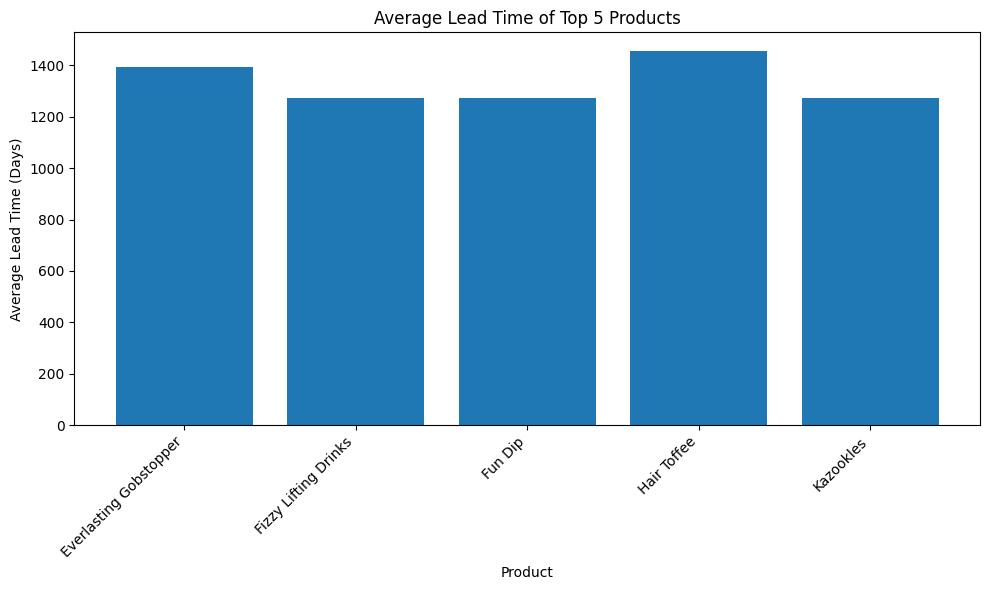

In [31]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(
    top_products.index,
    top_products["Average_Lead_Time"]
)

plt.xlabel("Product")
plt.ylabel("Average Lead Time (Days)")
plt.title("Average Lead Time of Top 5 Products")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

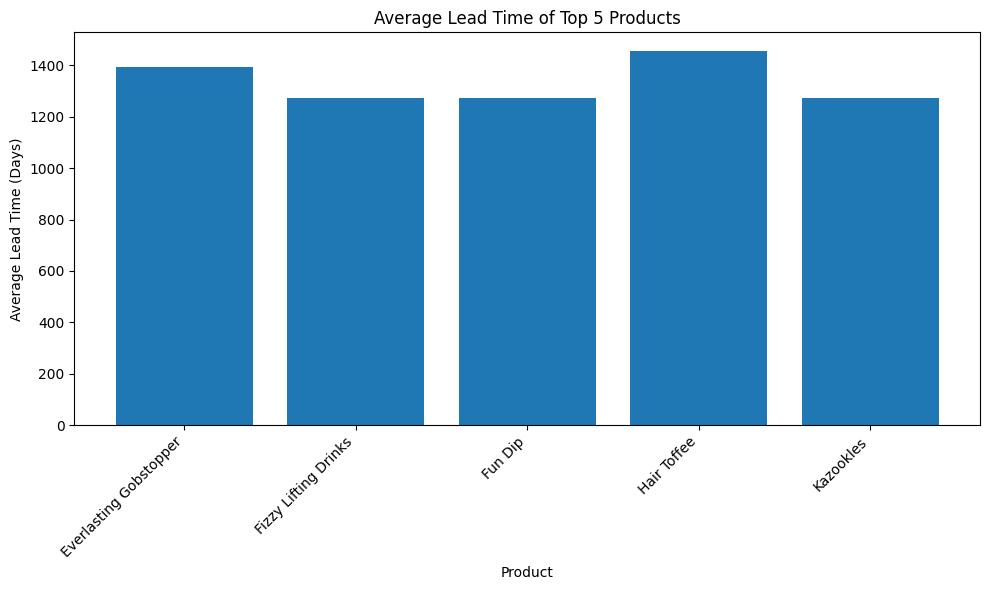

In [32]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.bar(top_products.index, top_products["Average_Lead_Time"])

plt.xlabel("Product")
plt.ylabel("Average Lead Time (Days)")
plt.title("Average Lead Time of Top 5 Products")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [33]:
product_analysis.columns

Index(['count', 'mean', 'median'], dtype='object')

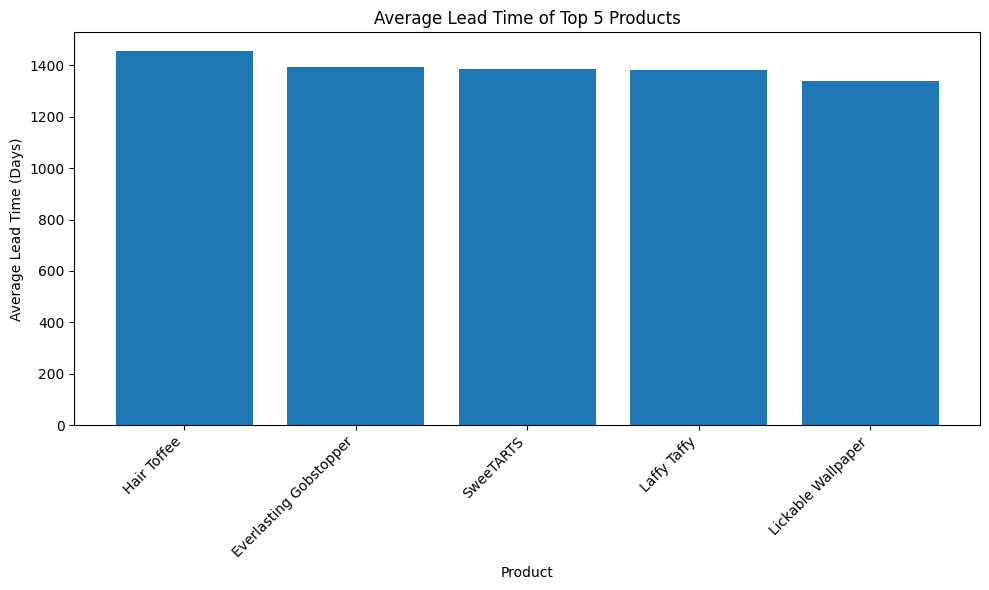

In [34]:
top_products = product_analysis.head(5)

plt.figure(figsize=(10, 6))

plt.bar(
    top_products.index,
    top_products["mean"]
)

plt.xlabel("Product")
plt.ylabel("Average Lead Time (Days)")
plt.title("Average Lead Time of Top 5 Products")
plt.xticks(rotation=45, ha="right")

plt.tight_layout()
plt.show()

In [35]:
product_analysis.sort_values(
    "mean",
    ascending=False
).head(10)

,count,mean,median
Product Name,,,
Hair Toffee,4,1455.250000,1455.0
Everlasting Gobstopper,3,1394.666667,1273.0
SweeTARTS,10,1383.500000,1274.0
Laffy Taffy,10,1383.100000,1275.0
Lickable Wallpaper,94,1339.138298,1274.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1274.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1274.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1274.0
Wonka Bar - Milk Chocolate,2137,1316.764623,1274.0


In [36]:
# Calculate shipping impact score
# Impact Score = order volume × average lead time

product_analysis["Impact_Score"] = (
    product_analysis["count"] * product_analysis["mean"]
)

product_analysis.sort_values(
    "Impact_Score",
    ascending=False
).head(10)

,count,mean,median,Impact_Score
Product Name,,,,
Wonka Bar - Milk Chocolate,2137,1316.764623,1274.0,2813926.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1274.0,2725805.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1274.0,2671207.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1274.0,2405337.0
Wonka Bar - Fudge Mallows,1818,1314.242024,1274.0,2389292.0
Wonka Gum,120,1306.525000,1273.5,156783.0
Lickable Wallpaper,94,1339.138298,1274.0,125879.0
Kazookles,96,1272.989583,1273.0,122207.0
SweeTARTS,10,1383.500000,1274.0,13835.0


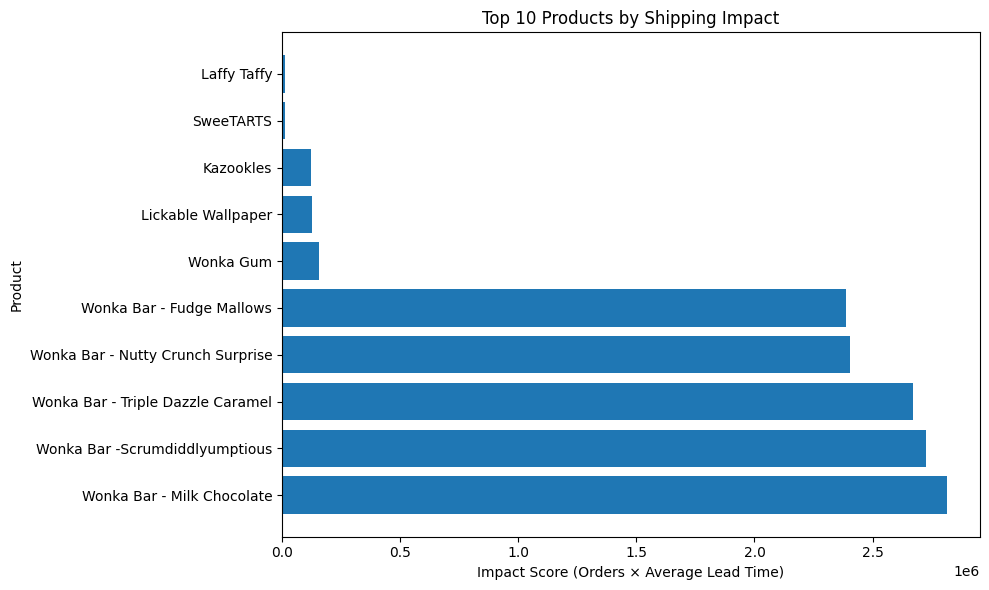

In [37]:
top_impact = product_analysis.sort_values(
    "Impact_Score",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_impact.index,
    top_impact["Impact_Score"]
)

plt.xlabel("Impact Score (Orders × Average Lead Time)")
plt.ylabel("Product")
plt.title("Top 10 Products by Shipping Impact")

plt.tight_layout()
plt.show()

In [38]:
ship_mode_analysis = df.groupby("Ship Mode")["Lead Time"].agg(
    ["count", "mean", "median"]
).sort_values("mean", ascending=False)

ship_mode_analysis

,count,mean,median
Ship Mode,,,
First Class,1548,1338.275840,1272.0
Same Day,547,1333.442413,1269.0
Second Class,1979,1323.845376,1273.0
Standard Class,6120,1314.334641,1274.0


In [39]:
df.columns.tolist()

['Row ID',
 'Order ID',
 'Order Date',
 'Ship Date',
 'Ship Mode',
 'Customer ID',
 'Country/Region',
 'City',
 'State/Province',
 'Postal Code',
 'Division',
 'Region',
 'Product ID',
 'Product Name',
 'Sales',
 'Units',
 'Gross Profit',
 'Cost',
 'Lead Time']

In [40]:
print("Lead Time" in df.columns)
print(df.columns.tolist())

True
['Row ID', 'Order ID', 'Order Date', 'Ship Date', 'Ship Mode', 'Customer ID', 'Country/Region', 'City', 'State/Province', 'Postal Code', 'Division', 'Region', 'Product ID', 'Product Name', 'Sales', 'Units', 'Gross Profit', 'Cost', 'Lead Time']


In [41]:
# Calculate Lead Time in days
df["Order Date"] = pd.to_datetime(df["Order Date"])
df["Ship Date"] = pd.to_datetime(df["Ship Date"])

df["Lead Time"] = (df["Ship Date"] - df["Order Date"]).dt.days

# Check the result
df[["Order Date", "Ship Date", "Lead Time"]].head()

,Order Date,Ship Date,Lead Time
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [42]:
print(df["Order Date"].head())
print(df["Ship Date"].head())

print("\nData types:")
print(df[["Order Date", "Ship Date"]].dtypes)

0   2024-01-03
1   2024-01-04
2   2024-01-04
3   2024-01-04
4   2024-01-05
Name: Order Date, dtype: datetime64[ns]
0   2026-06-30
1   2026-07-01
2   2026-07-01
3   2026-07-01
4   2026-07-05
Name: Ship Date, dtype: datetime64[ns]

Data types:
Order Date    datetime64[ns]
Ship Date     datetime64[ns]
dtype: object


In [43]:
df.groupby(df["Order Date"].dt.year)["Lead Time"].agg(
    ["count", "mean", "median"]
)

,count,mean,median
Order Date,,,
2024,4181,1094.018417,1269.0
2025,6013,1478.558290,1637.0


In [44]:
# Convert dates using DD-MM-YYYY format
df["Order Date"] = pd.to_datetime(
    df["Order Date"],
    format="%d-%m-%Y"
)

df["Ship Date"] = pd.to_datetime(
    df["Ship Date"],
    format="%d-%m-%Y"
)

# Calculate Lead Time in days
df["Lead Time"] = (
    df["Ship Date"] - df["Order Date"]
).dt.days

# Check the result
df[["Order Date", "Ship Date", "Lead Time"]].head()

,Order Date,Ship Date,Lead Time
0,2024-01-03,2026-06-30,909
1,2024-01-04,2026-07-01,909
2,2024-01-04,2026-07-01,909
3,2024-01-04,2026-07-01,909
4,2024-01-05,2026-07-05,912


In [45]:
ship_mode_analysis = (
    df.groupby("Ship Mode")["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

ship_mode_analysis

,count,mean,median
Ship Mode,,,
First Class,1548,1338.275840,1272.0
Same Day,547,1333.442413,1269.0
Second Class,1979,1323.845376,1273.0
Standard Class,6120,1314.334641,1274.0


In [46]:
# Calculate overall lead time
overall_lead_time = df["Lead Time"].mean()

print("Overall Average Lead Time:", round(overall_lead_time, 2))

# Calculate lead time by product
product_analysis = (
    df.groupby("Product Name")["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

product_analysis.head(10)

Overall Average Lead Time: 1320.84


,count,mean,median
Product Name,,,
Hair Toffee,4,1455.250000,1455.0
Everlasting Gobstopper,3,1394.666667,1273.0
SweeTARTS,10,1383.500000,1274.0
Laffy Taffy,10,1383.100000,1275.0
Lickable Wallpaper,94,1339.138298,1274.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1274.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1274.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1274.0
Wonka Bar - Milk Chocolate,2137,1316.764623,1274.0


In [47]:
# Filter products with at least 20 orders
reliable_products = product_analysis[
    product_analysis["count"] >= 20
].copy()

# Sort by average lead time
reliable_products = reliable_products.sort_values(
    "mean",
    ascending=False
)

reliable_products.head(10)

,count,mean,median
Product Name,,,
Lickable Wallpaper,94,1339.138298,1274.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1274.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1274.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1274.0
Wonka Bar - Milk Chocolate,2137,1316.764623,1274.0
Wonka Bar - Fudge Mallows,1818,1314.242024,1274.0
Wonka Gum,120,1306.525000,1273.5
Kazookles,96,1272.989583,1273.0


In [48]:
# Calculate potential lead-time reduction for reliable products

reliable_products["Potential_Reduction_10%"] = (
    reliable_products["mean"] * 0.10
)

reliable_products["Projected_Lead_Time"] = (
    reliable_products["mean"] * 0.90
)

reliable_products[
    ["Potential_Reduction_10%", "Projected_Lead_Time"]
].head(10)

,Potential_Reduction_10%,Projected_Lead_Time
Product Name,,
Lickable Wallpaper,133.913830,1205.224468
Wonka Bar - Nutty Crunch Surprise,132.891547,1196.023923
Wonka Bar - Triple Dazzle Caramel,132.566104,1193.094938
Wonka Bar -Scrumdiddlyumptious,132.064196,1188.577762
Wonka Bar - Milk Chocolate,131.676462,1185.088161
Wonka Bar - Fudge Mallows,131.424202,1182.817822
Wonka Gum,130.652500,1175.872500
Kazookles,127.298958,1145.690625


In [49]:
# Calculate total potential lead-time savings

total_saved = (
    reliable_products["Potential_Reduction_10%"] 
    * reliable_products["count"]
).sum()

total_orders = reliable_products["count"].sum()

average_saving_per_order = total_saved / total_orders

print("Total Potential Lead-Time Saved:", round(total_saved, 2))
print("Average Potential Saving per Order:", round(average_saving_per_order, 2))

Total Potential Lead-Time Saved: 1341043.6
Average Potential Saving per Order: 132.07


In [50]:
# Create a summary table for the optimization analysis

optimization_summary = reliable_products[
    ["Potential_Reduction_10%", "Projected_Lead_Time"]
].copy()

optimization_summary["Orders"] = reliable_products["count"]
optimization_summary["Current_Lead_Time"] = reliable_products["mean"]

optimization_summary = optimization_summary[
    [
        "Orders",
        "Current_Lead_Time",
        "Potential_Reduction_10%",
        "Projected_Lead_Time"
    ]
]

optimization_summary

,Orders,Current_Lead_Time,Potential_Reduction_10%,Projected_Lead_Time
Product Name,,,,
Lickable Wallpaper,94,1339.138298,133.913830,1205.224468
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,132.891547,1196.023923
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,132.566104,1193.094938
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,132.064196,1188.577762
Wonka Bar - Milk Chocolate,2137,1316.764623,131.676462,1185.088161
Wonka Bar - Fudge Mallows,1818,1314.242024,131.424202,1182.817822
Wonka Gum,120,1306.525000,130.652500,1175.872500
Kazookles,96,1272.989583,127.298958,1145.690625


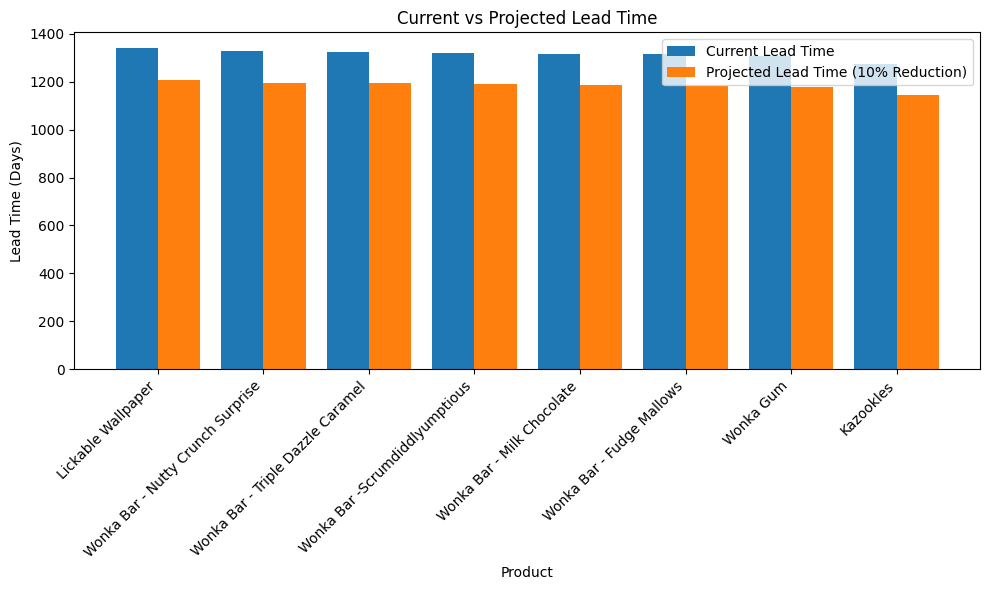

In [51]:
import matplotlib.pyplot as plt

# Plot current vs projected lead time
plt.figure(figsize=(10, 6))

x = range(len(optimization_summary))

plt.bar(
    [i - 0.2 for i in x],
    optimization_summary["Current_Lead_Time"],
    width=0.4,
    label="Current Lead Time"
)

plt.bar(
    [i + 0.2 for i in x],
    optimization_summary["Projected_Lead_Time"],
    width=0.4,
    label="Projected Lead Time (10% Reduction)"
)

plt.xticks(
    x,
    optimization_summary.index,
    rotation=45,
    ha="right"
)

plt.xlabel("Product")
plt.ylabel("Lead Time (Days)")
plt.title("Current vs Projected Lead Time")
plt.legend()

plt.tight_layout()
plt.show()

In [52]:
# Final Optimization KPI Summary

print("=" * 55)
print("NASSAU CANDY DISTRIBUTION - OPTIMIZATION KPIs")
print("=" * 55)

print(f"Total Orders Analyzed: {len(df):,}")
print(f"Overall Average Lead Time: {df['Lead Time'].mean():.2f} days")
print(f"Overall Median Lead Time: {df['Lead Time'].median():.2f} days")

print("\nOptimization Scenario (10% Reduction):")
print(f"Products Analyzed: {len(reliable_products)}")
print(f"Total Potential Lead-Time Saved: {total_saved:,.2f} days")
print(f"Average Potential Saving per Order: {average_saving_per_order:.2f} days")

print("\nPriority Products:")
print(reliable_products.sort_values("mean", ascending=False).head(5))

NASSAU CANDY DISTRIBUTION - OPTIMIZATION KPIs
Total Orders Analyzed: 10,194
Overall Average Lead Time: 1320.84 days
Overall Median Lead Time: 1274.00 days

Optimization Scenario (10% Reduction):
Products Analyzed: 8
Total Potential Lead-Time Saved: 1,341,043.60 days
Average Potential Saving per Order: 132.07 days

Priority Products:
                                   count         mean  median  \
Product Name                                                    
Lickable Wallpaper                    94  1339.138298  1274.0   
Wonka Bar - Nutty Crunch Surprise   1810  1328.915470  1274.0   
Wonka Bar - Triple Dazzle Caramel   2015  1325.661042  1274.0   
Wonka Bar -Scrumdiddlyumptious      2064  1320.641957  1274.0   
Wonka Bar - Milk Chocolate          2137  1316.764623  1274.0   

                                   Potential_Reduction_10%  \
Product Name                                                 
Lickable Wallpaper                              133.913830   
Wonka Bar - Nutty Crunc

In [53]:
monthly_2025 = (
    df[df["Order Date"].dt.year == 2025]
    .groupby(df["Order Date"].dt.month)["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

monthly_2025

,count,mean,median
Order Date,,,
1,256,1502.621094,1637.0
10,508,1495.681102,1637.0
3,411,1490.739659,1637.0
12,848,1481.094340,1637.0
2,190,1478.594737,1636.0
9,831,1477.620939,1636.0
8,402,1476.166667,1636.0
11,830,1475.708434,1636.0
6,451,1472.419069,1636.0


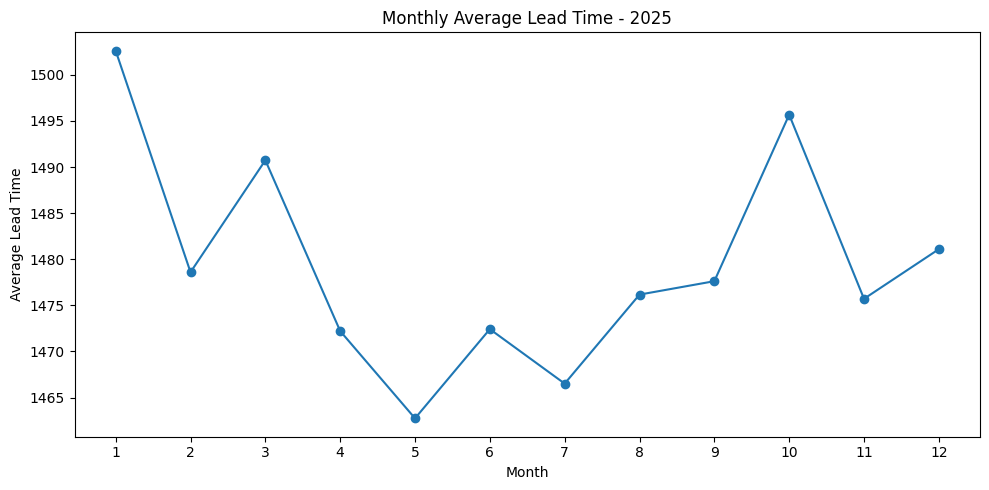

In [54]:
monthly_trend = (
    df[df["Order Date"].dt.year == 2025]
    .groupby(df["Order Date"].dt.month)["Lead Time"]
    .mean()
)

plt.figure(figsize=(10, 5))
plt.plot(monthly_trend.index, monthly_trend.values, marker="o")

plt.xlabel("Month")
plt.ylabel("Average Lead Time")
plt.title("Monthly Average Lead Time - 2025")
plt.xticks(range(1, 13))

plt.tight_layout()
plt.show()

In [55]:
shipping_mode_analysis = (
    df.groupby("Ship Mode")["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

shipping_mode_analysis

,count,mean,median
Ship Mode,,,
First Class,1548,1338.275840,1272.0
Same Day,547,1333.442413,1269.0
Second Class,1979,1323.845376,1273.0
Standard Class,6120,1314.334641,1274.0


In [56]:
year_ship_analysis = (
    df.groupby([df["Order Date"].dt.year, "Ship Mode"])["Lead Time"]
    .mean()
    .unstack()
)

year_ship_analysis

Ship Mode,First Class,Same Day,Second Class,Standard Class
Order Date,,,,
2024,1087.546392,1101.970149,1098.137761,1093.561702
2025,1489.336439,1467.910405,1481.221269,1475.776803


In [57]:
year_ship_change = year_ship_analysis.copy()

year_ship_change.loc["Increase_%"] = (
    (year_ship_change.loc[2025] - year_ship_change.loc[2024])
    / year_ship_change.loc[2024]
) * 100

year_ship_change

Ship Mode,First Class,Same Day,Second Class,Standard Class
Order Date,,,,
2024,1087.546392,1101.970149,1098.137761,1093.561702
2025,1489.336439,1467.910405,1481.221269,1475.776803
Increase_%,36.944635,33.207819,34.884832,34.951398


In [58]:
# Calculate shipping impact score

# Create the old column names as aliases for compatibility
product_analysis["Orders"] = product_analysis["count"]
product_analysis["Average_Lead_Time"] = product_analysis["mean"]

# Impact Score = order volume × average lead time
product_analysis["Impact_Score"] = (
    product_analysis["Orders"] *
    product_analysis["Average_Lead_Time"]
)

# Get the 10 highest-impact products
top_impact = (
    product_analysis
    .sort_values("Impact_Score", ascending=False)
    .head(10)
)

top_impact[
    ["Orders", "Average_Lead_Time", "Impact_Score"]
]

,Orders,Average_Lead_Time,Impact_Score
Product Name,,,
Wonka Bar - Milk Chocolate,2137,1316.764623,2813926.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,2725805.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,2671207.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,2405337.0
Wonka Bar - Fudge Mallows,1818,1314.242024,2389292.0
Wonka Gum,120,1306.525000,156783.0
Lickable Wallpaper,94,1339.138298,125879.0
Kazookles,96,1272.989583,122207.0
SweeTARTS,10,1383.500000,13835.0


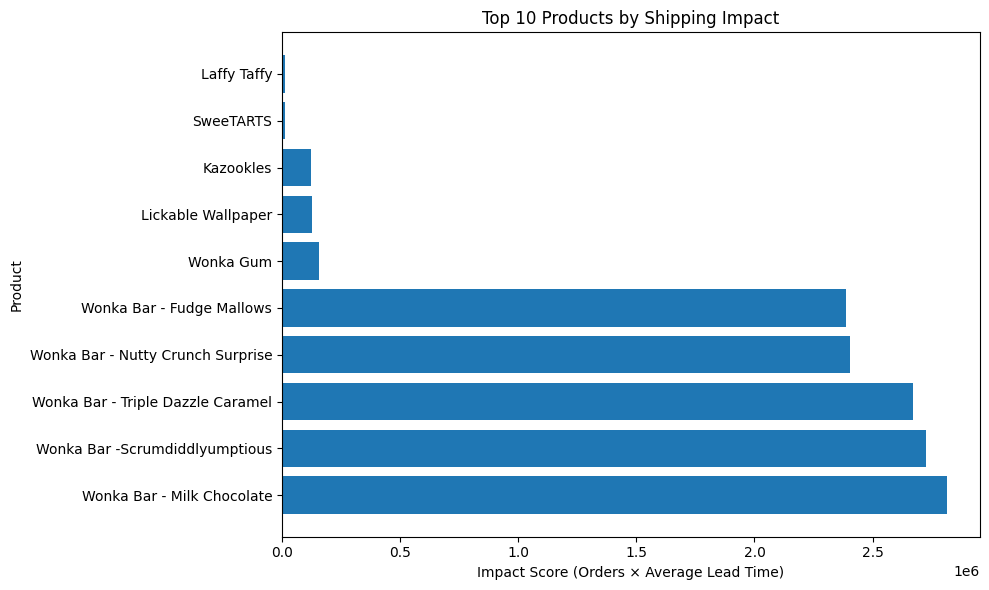

In [59]:
top_impact = product_analysis.sort_values(
    "Impact_Score",
    ascending=False
).head(10)

plt.figure(figsize=(10, 6))

plt.barh(
    top_impact.index,
    top_impact["Impact_Score"]
)

plt.xlabel("Impact Score (Orders × Average Lead Time)")
plt.ylabel("Product")
plt.title("Top 10 Products by Shipping Impact")

plt.tight_layout()
plt.show()

In [60]:
impact_shipping = (
    df[df["Product Name"].isin(top_impact.index)]
    .groupby("Ship Mode")["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

impact_shipping

,count,mean,median
Ship Mode,,,
First Class,1544,1338.448834,1272.0
Same Day,546,1332.890110,1269.0
Second Class,1977,1323.898331,1273.0
Standard Class,6107,1314.300311,1274.0


In [61]:
product_ship_analysis = (
    df[df["Product Name"].isin(top_impact.index)]
    .groupby(["Product Name", "Ship Mode"])["Lead Time"]
    .agg(["count", "mean", "median"])
    .sort_values("mean", ascending=False)
)

product_ship_analysis

,,count,mean,median
Product Name,Ship Mode,,,
Laffy Taffy,Same Day,1,1635.000000,1635.0
SweeTARTS,Second Class,3,1516.666667,1638.0
Lickable Wallpaper,Second Class,19,1406.789474,1637.0
Wonka Bar - Nutty Crunch Surprise,Same Day,103,1390.000000,1269.0
Laffy Taffy,Standard Class,7,1379.000000,1275.0
Wonka Gum,Same Day,7,1373.857143,1270.0
Lickable Wallpaper,First Class,19,1367.736842,1272.0
Wonka Gum,Second Class,24,1364.083333,1274.0
Wonka Bar -Scrumdiddlyumptious,First Class,328,1351.664634,1272.0


In [62]:
reliable_product_ship = (
    product_ship_analysis[
        product_ship_analysis["count"] >= 20
    ]
    .sort_values("mean", ascending=False)
)

reliable_product_ship.head(10)

count         mean  median
Product Name                      Ship Mode                               
Wonka Bar - Nutty Crunch Surprise Same Day        103  1390.000000  1269.0
Wonka Gum                         Second Class     24  1364.083333  1274.0
Wonka Bar -Scrumdiddlyumptious    First Class     328  1351.664634  1272.0
Wonka Bar - Triple Dazzle Caramel First Class     277  1349.335740  1272.0
                                  Same Day        115  1345.600000  1269.0
Wonka Bar - Fudge Mallows         First Class     276  1336.355072  1272.0
                                  Second Class    346  1332.673410  1273.0
Wonka Bar - Milk Chocolate        First Class     313  1331.022364  1272.0
Wonka Bar - Nutty Crunch Surprise First Class     286  1330.167832  1272.0
Wonka Bar - Milk Chocolate        Second Class    403  1329.781638  1273.0

In [63]:
product_summary = (
    df.groupby("Product Name")
    .agg(
        Orders=("Product Name", "count"),
        Average_Lead_Time=("Lead Time", "mean")
    )
)

product_summary["Impact_Score"] = (
    product_summary["Orders"] * product_summary["Average_Lead_Time"]
)

product_summary.sort_values(
    "Impact_Score",
    ascending=False
).head(10)

,Orders,Average_Lead_Time,Impact_Score
Product Name,,,
Wonka Bar - Milk Chocolate,2137,1316.764623,2813926.0
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,2725805.0
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,2671207.0
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,2405337.0
Wonka Bar - Fudge Mallows,1818,1314.242024,2389292.0
Wonka Gum,120,1306.525000,156783.0
Lickable Wallpaper,94,1339.138298,125879.0
Kazookles,96,1272.989583,122207.0
SweeTARTS,10,1383.500000,13835.0


In [64]:
overall_lead_time = df["Lead Time"].mean()

top_products = product_summary.sort_values(
    "Impact_Score",
    ascending=False
).head(5)

top_products["Difference_From_Overall"] = (
    top_products["Average_Lead_Time"] - overall_lead_time
)

top_products

,Orders,Average_Lead_Time,Impact_Score,Difference_From_Overall
Product Name,,,,
Wonka Bar - Milk Chocolate,2137,1316.764623,2813926.0,-4.077244
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,2725805.0,-0.199910
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,2671207.0,4.819174
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,2405337.0,8.073602
Wonka Bar - Fudge Mallows,1818,1314.242024,2389292.0,-6.599844


In [65]:
# Calculate the potential lead-time reduction for the top 5 products

top_products["Potential_Reduction_10%"] = (
    top_products["Average_Lead_Time"] * 0.10
)

top_products["Projected_Lead_Time"] = (
    top_products["Average_Lead_Time"] * 0.90
)

top_products[
    [
        "Orders",
        "Average_Lead_Time",
        "Potential_Reduction_10%",
        "Projected_Lead_Time"
    ]
]

,Orders,Average_Lead_Time,Potential_Reduction_10%,Projected_Lead_Time
Product Name,,,,
Wonka Bar - Milk Chocolate,2137,1316.764623,131.676462,1185.088161
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,132.064196,1188.577762
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,132.566104,1193.094938
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,132.891547,1196.023923
Wonka Bar - Fudge Mallows,1818,1314.242024,131.424202,1182.817822


In [66]:
# Estimate total lead-time reduction across the top 5 products

top_products["Total_Current_Lead_Time"] = (
    top_products["Orders"] * top_products["Average_Lead_Time"]
)

top_products["Total_Projected_Lead_Time"] = (
    top_products["Orders"] * top_products["Projected_Lead_Time"]
)

top_products["Total_Lead_Time_Saved"] = (
    top_products["Total_Current_Lead_Time"]
    - top_products["Total_Projected_Lead_Time"]
)

top_products[
    [
        "Orders",
        "Average_Lead_Time",
        "Projected_Lead_Time",
        "Total_Lead_Time_Saved"
    ]
]

,Orders,Average_Lead_Time,Projected_Lead_Time,Total_Lead_Time_Saved
Product Name,,,,
Wonka Bar - Milk Chocolate,2137,1316.764623,1185.088161,281392.6
Wonka Bar -Scrumdiddlyumptious,2064,1320.641957,1188.577762,272580.5
Wonka Bar - Triple Dazzle Caramel,2015,1325.661042,1193.094938,267120.7
Wonka Bar - Nutty Crunch Surprise,1810,1328.915470,1196.023923,240533.7
Wonka Bar - Fudge Mallows,1818,1314.242024,1182.817822,238929.2


In [67]:
total_saved = top_products["Total_Lead_Time_Saved"].sum()

print("Total Potential Lead-Time Saved:", round(total_saved, 2))
print("Average Potential Saving per Order:",
      round(total_saved / top_products["Orders"].sum(), 2))

Total Potential Lead-Time Saved: 1300556.7
Average Potential Saving per Order: 132.12


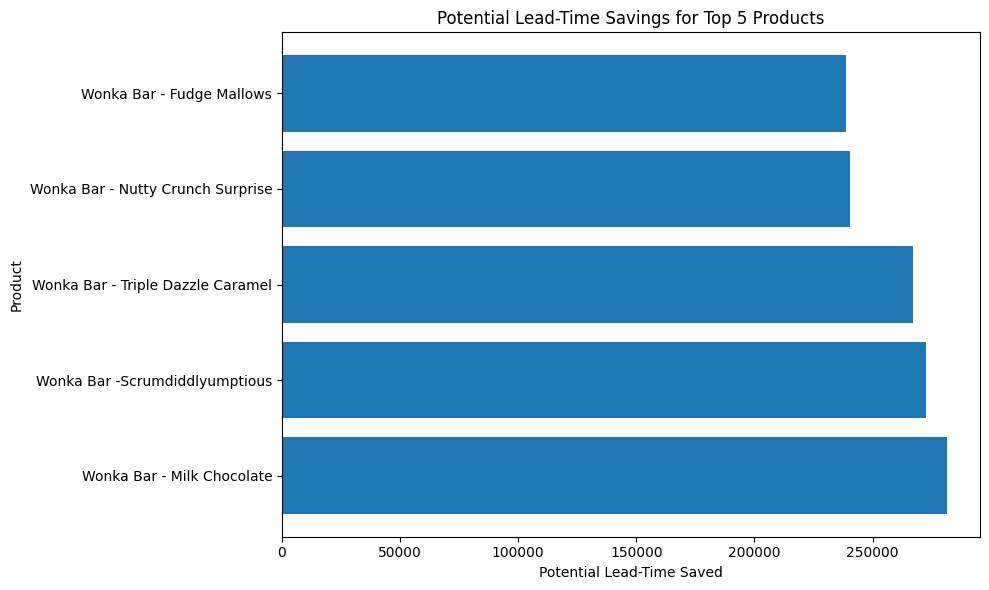

In [68]:
import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))

plt.barh(
    top_products.index,
    top_products["Total_Lead_Time_Saved"]
)

plt.xlabel("Potential Lead-Time Saved")
plt.ylabel("Product")
plt.title("Potential Lead-Time Savings for Top 5 Products")

plt.tight_layout()
plt.show()

In [69]:
# Final optimization summary

print("FINAL OPTIMIZATION SUMMARY")
print("-" * 40)

print("Total Potential Lead-Time Saved:",
      round(top_products["Total_Lead_Time_Saved"].sum(), 2))

print("Average Potential Saving per Order:",
      round(
          top_products["Total_Lead_Time_Saved"].sum()
          / top_products["Orders"].sum(),
          2
      ))

print("\nTop Product for Optimization:")
print(top_products.index[0])

print("\nTop 5 Products by Potential Saving:")
print(top_products[
    ["Orders", "Average_Lead_Time", "Total_Lead_Time_Saved"]
])

FINAL OPTIMIZATION SUMMARY
----------------------------------------
Total Potential Lead-Time Saved: 1300556.7
Average Potential Saving per Order: 132.12

Top Product for Optimization:
Wonka Bar - Milk Chocolate

Top 5 Products by Potential Saving:
                                   Orders  Average_Lead_Time  \
Product Name                                                   
Wonka Bar - Milk Chocolate           2137        1316.764623   
Wonka Bar -Scrumdiddlyumptious       2064        1320.641957   
Wonka Bar - Triple Dazzle Caramel    2015        1325.661042   
Wonka Bar - Nutty Crunch Surprise    1810        1328.915470   
Wonka Bar - Fudge Mallows            1818        1314.242024   

                                   Total_Lead_Time_Saved  
Product Name                                              
Wonka Bar - Milk Chocolate                      281392.6  
Wonka Bar -Scrumdiddlyumptious                  272580.5  
Wonka Bar - Triple Dazzle Caramel               267120.7  
Wonka B

In [70]:
# Overall Project KPIs

print("NASSAU CANDY DISTRIBUTION - OPTIMIZATION KPIs")
print("=" * 55)

print(f"Total Orders Analyzed: {len(df):,}")
print(f"Overall Average Lead Time: {df['Lead Time'].mean():.2f}")
print(f"Overall Median Lead Time: {df['Lead Time'].median():.2f}")

print("\n2024 vs 2025:")
print(f"2024 Average Lead Time: {df[df['Order Date'].dt.year == 2024]['Lead Time'].mean():.2f}")
print(f"2025 Average Lead Time: {df[df['Order Date'].dt.year == 2025]['Lead Time'].mean():.2f}")

print("\nOptimization:")
print(f"Potential Lead-Time Saved: {top_products['Total_Lead_Time_Saved'].sum():,.2f}")
print(f"Average Saving per Order: {top_products['Total_Lead_Time_Saved'].sum() / top_products['Orders'].sum():.2f}")

print("\nPriority Product:")
print(top_products.index[0])

NASSAU CANDY DISTRIBUTION - OPTIMIZATION KPIs
Total Orders Analyzed: 10,194
Overall Average Lead Time: 1320.84
Overall Median Lead Time: 1274.00

2024 vs 2025:
2024 Average Lead Time: 1094.02
2025 Average Lead Time: 1478.56

Optimization:
Potential Lead-Time Saved: 1,300,556.70
Average Saving per Order: 132.12

Priority Product:
Wonka Bar - Milk Chocolate
